# Model 2 — Improved CLIP + LSTM/GRU Decoder

This notebook trains **Model 2** for the ANN project.

The goal is:

```text
best frame image  →  short generated query/caption
```

This improved version fixes the previous weak behavior by:

- removing GPT-2 completely,
- using CLIP only as a **frozen image encoder**,
- training our own **LSTM and GRU decoders**,
- injecting the CLIP image feature into the decoder at **every generated word**, not only at the start,
- adding a **CLIP retrieval baseline** for comparison,
- using short caption length to reduce story-like outputs,
- showing different random test samples every time the qualitative cell is run.

No extra installation cells are used.

## 1. Mount Google Drive

The project files are expected to be inside your shared Google Drive folder.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Import libraries

No `pip install` commands are used. The notebook uses libraries available in Colab / your current environment.

In [ ]:
import os
import re
import json
import math
import glob
import time
import random
import textwrap
from collections import Counter

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as T

import matplotlib.pyplot as plt
from IPython.display import display

from transformers import CLIPModel, CLIPTokenizer

print('Torch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

Torch version: 2.10.0+cu128
CUDA available: True


## 3. Configuration

Change `PROJECT_ROOT` only if your shared Drive folder has a different name/path.

`MAX_CAPTION_WORDS` is kept short because our target is a short query, not a long story.

In [ ]:
PROJECT_ROOT = '/content/drive/MyDrive/thumbnail_project'
PROCESSED_DIR = os.path.join(PROJECT_ROOT, 'processed')
FRAMES_ROOT = os.path.join(PROJECT_ROOT, 'qvh_frames')
EXPORT_DIR = os.path.join(PROJECT_ROOT, 'exports', 'model2_clip_lstm_gru_improved')
os.makedirs(EXPORT_DIR, exist_ok=True)

PAIRS_PATH = os.path.join(PROCESSED_DIR, 'm2_train_pairs.jsonl')

# Main hyperparameters
SEED = 42
BATCH_SIZE = 16
MAX_CAPTION_WORDS = 15       # recommended: 12-15 for query-like text
MIN_WORD_FREQ = 2
MAX_VOCAB_SIZE = 2000

EMBED_DIM = 128
IMAGE_EMBED_DIM = 256
HIDDEN_DIM = 256
DROPOUT = 0.35
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 25
PATIENCE = 4
GRAD_CLIP = 1.0

CLIP_MODEL_NAME = 'openai/clip-vit-base-patch32'

# Reproducibility for training split/training behavior.
# Qualitative sample display later uses SystemRandom so it changes each run.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
print('Pairs path:', PAIRS_PATH)
print('Frames root:', FRAMES_ROOT)
print('Export dir:', EXPORT_DIR)

Using device: cuda
Pairs path: /content/drive/MyDrive/thumbnail_project/processed/m2_train_pairs.jsonl
Frames root: /content/drive/MyDrive/thumbnail_project/qvh_frames
Export dir: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru_improved


## 4. Load the image-text pairs

Each row contains a selected best frame and its corresponding query/caption text.

In [ ]:
assert os.path.exists(PAIRS_PATH), f'Could not find {PAIRS_PATH}'

records = []
with open(PAIRS_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if line:
            records.append(json.loads(line))

df = pd.DataFrame(records)
print('Loaded pairs:', len(df))
print(df.head())

Loaded pairs: 1608
   qid                                         frame_path  \
0    1  /content/drive/MyDrive/thumbnail_project/qvh_f...   
1    6  /content/drive/MyDrive/thumbnail_project/qvh_f...   
2   11  /content/drive/MyDrive/thumbnail_project/qvh_f...   
3   16  /content/drive/MyDrive/thumbnail_project/qvh_f...   
4   27  /content/drive/MyDrive/thumbnail_project/qvh_f...   

                                              query                      vid  \
0  Woman wears a white top walking down the street.  Q2TqU-Oh7KQ_360.0_510.0   
1                 A woman is introducing her family  9c_w8HU3hqc_360.0_510.0   
2        Blonde woman is walking up a grassy field.  0gzFURbCXoE_210.0_360.0   
3                       Man is leaning with a boat.   u-61297MT1I_60.0_210.0   
4                   Video shows the Bluetooth sign.  t_9gaLdfc_Y_210.0_360.0   

   best_timestamp  mean_saliency  
0              73          3.667  
1             103          3.667  
2               9          3

## 5. Fix frame paths

The JSON file may contain old Colab paths. This cell maps each old path to the actual image file inside `qvh_frames` using the image filename.

In [ ]:
image_exts = ('*.jpg', '*.jpeg', '*.png', '*.webp')
all_image_files = []
for ext in image_exts:
    all_image_files.extend(glob.glob(os.path.join(FRAMES_ROOT, '**', ext), recursive=True))

basename_to_path = {os.path.basename(p): p for p in all_image_files}
print('Images found under qvh_frames:', len(all_image_files))


def resolve_frame_path(old_path):
    if isinstance(old_path, str) and os.path.exists(old_path):
        return old_path
    base = os.path.basename(str(old_path))
    return basename_to_path.get(base, None)

# Use frame_path from JSONL. If your file uses a different column, change it here.
df['image_path'] = df['frame_path'].apply(resolve_frame_path)
df['caption'] = df['query'].astype(str)

missing = df['image_path'].isna().sum()
print('Missing image paths:', missing)

df = df.dropna(subset=['image_path', 'caption']).reset_index(drop=True)
print('Usable pairs:', len(df))
print(df[['image_path', 'caption']].head())

Images found under qvh_frames: 1595
Missing image paths: 0
Usable pairs: 1608
                                          image_path  \
0  /content/drive/MyDrive/thumbnail_project/qvh_f...   
1  /content/drive/MyDrive/thumbnail_project/qvh_f...   
2  /content/drive/MyDrive/thumbnail_project/qvh_f...   
3  /content/drive/MyDrive/thumbnail_project/qvh_f...   
4  /content/drive/MyDrive/thumbnail_project/qvh_f...   

                                            caption  
0  Woman wears a white top walking down the street.  
1                 A woman is introducing her family  
2        Blonde woman is walking up a grassy field.  
3                       Man is leaning with a boat.  
4                   Video shows the Bluetooth sign.  


## 6. Clean captions

We keep the target text simple and limit it to a short query-like sentence.

In [ ]:
def clean_caption(text):
    text = str(text).lower().strip()
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def tokenize(text):
    return clean_caption(text).split()


df['clean_caption'] = df['caption'].apply(clean_caption)
df['num_words'] = df['clean_caption'].apply(lambda x: len(x.split()))

df = df[df['num_words'] > 0].reset_index(drop=True)
print('Pairs after caption cleaning:', len(df))
print(df[['caption', 'clean_caption', 'num_words']].head())
print('Caption length summary:')
print(df['num_words'].describe())

Pairs after caption cleaning: 1608
                                            caption  \
0  Woman wears a white top walking down the street.   
1                 A woman is introducing her family   
2        Blonde woman is walking up a grassy field.   
3                       Man is leaning with a boat.   
4                   Video shows the Bluetooth sign.   

                                     clean_caption  num_words  
0  woman wears a white top walking down the street          9  
1                a woman is introducing her family          6  
2        blonde woman is walking up a grassy field          8  
3                       man is leaning with a boat          6  
4                   video shows the bluetooth sign          5  
Caption length summary:
count    1608.000000
mean       10.333333
std         3.661751
min         4.000000
25%         8.000000
50%        10.000000
75%        12.000000
max        34.000000
Name: num_words, dtype: float64


## 7. Split by video id

We split by `vid` when possible. This reduces leakage where very similar frames from the same video appear in both train and test.

In [ ]:
if 'vid' not in df.columns:
    df['vid'] = df['image_path'].apply(lambda p: os.path.splitext(os.path.basename(p))[0])

unique_vids = sorted(df['vid'].astype(str).unique())
rng = random.Random(SEED)
rng.shuffle(unique_vids)

n = len(unique_vids)
n_train = int(0.80 * n)
n_val = int(0.10 * n)

train_vids = set(unique_vids[:n_train])
val_vids = set(unique_vids[n_train:n_train+n_val])
test_vids = set(unique_vids[n_train+n_val:])

train_df = df[df['vid'].astype(str).isin(train_vids)].reset_index(drop=True)
val_df = df[df['vid'].astype(str).isin(val_vids)].reset_index(drop=True)
test_df = df[df['vid'].astype(str).isin(test_vids)].reset_index(drop=True)

print('Train:', len(train_df), 'Val:', len(val_df), 'Test:', len(test_df))
print('Unique videos:', len(unique_vids))

Train: 1284 Val: 159 Test: 165
Unique videos: 1595


## 8. Build vocabulary

The vocabulary is built only from training captions. Rare words are mapped to `<UNK>` to reduce memorization.

In [ ]:
PAD_TOKEN = '<PAD>'
BOS_TOKEN = '<BOS>'
EOS_TOKEN = '<EOS>'
UNK_TOKEN = '<UNK>'

counter = Counter()
for cap in train_df['clean_caption']:
    counter.update(tokenize(cap))

specials = [PAD_TOKEN, BOS_TOKEN, EOS_TOKEN, UNK_TOKEN]
words = [w for w, c in counter.most_common() if c >= MIN_WORD_FREQ]
words = words[:max(0, MAX_VOCAB_SIZE - len(specials))]

itos = specials + words
stoi = {w: i for i, w in enumerate(itos)}

PAD_IDX = stoi[PAD_TOKEN]
BOS_IDX = stoi[BOS_TOKEN]
EOS_IDX = stoi[EOS_TOKEN]
UNK_IDX = stoi[UNK_TOKEN]
VOCAB_SIZE = len(itos)

print('Vocabulary size:', VOCAB_SIZE)
print('Most common words:', counter.most_common(20))

Vocabulary size: 946
Most common words: [('a', 1465), ('in', 535), ('the', 480), ('woman', 423), ('is', 306), ('and', 304), ('of', 280), ('on', 234), ('man', 233), ('with', 177), ('her', 170), ('to', 154), ('are', 123), ('at', 95), ('white', 85), ('talking', 79), ('girl', 78), ('while', 74), ('black', 73), ('from', 73)]


## 9. Encode and decode captions

We add `<BOS>` at the start and `<EOS>` at the end. Captions are padded to a fixed length.

In [ ]:
SEQ_LEN = MAX_CAPTION_WORDS + 2  # BOS + words + EOS


def encode_caption(text):
    words = tokenize(text)[:MAX_CAPTION_WORDS]
    ids = [BOS_IDX] + [stoi.get(w, UNK_IDX) for w in words] + [EOS_IDX]
    if len(ids) < SEQ_LEN:
        ids += [PAD_IDX] * (SEQ_LEN - len(ids))
    else:
        ids = ids[:SEQ_LEN]
        ids[-1] = EOS_IDX
    return torch.tensor(ids, dtype=torch.long)


def decode_ids(ids):
    words = []
    for idx in ids:
        idx = int(idx)
        if idx == EOS_IDX:
            break
        if idx in (PAD_IDX, BOS_IDX):
            continue
        words.append(itos[idx] if idx < len(itos) else UNK_TOKEN)
    return ' '.join(words)

sample = train_df.iloc[0]['clean_caption']
encoded = encode_caption(sample)
print('Original:', sample)
print('Encoded:', encoded.tolist())
print('Decoded:', decode_ids(encoded.tolist()))

Original: woman wears a white top walking down the street
Encoded: [1, 7, 87, 4, 18, 27, 52, 37, 6, 58, 2, 0, 0, 0, 0, 0, 0]
Decoded: woman wears a white top walking down the street


## 10. Image transforms

The images are normalized using CLIP's image normalization values. Training uses light augmentation only.

In [ ]:
CLIP_MEAN = [0.48145466, 0.4578275, 0.40821073]
CLIP_STD = [0.26862954, 0.26130258, 0.27577711]

train_transform = T.Compose([
    T.Resize(256),
    T.RandomResizedCrop(224, scale=(0.85, 1.0)),
    T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
    T.RandomRotation(degrees=3),
    T.ToTensor(),
    T.Normalize(mean=CLIP_MEAN, std=CLIP_STD),
])

val_test_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=CLIP_MEAN, std=CLIP_STD),
])

## 11. Dataset and DataLoader

Each sample returns the image tensor, the encoded caption, and metadata for display.

In [ ]:
class FrameCaptionDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        image_tensor = self.transform(image)
        caption_tensor = encode_caption(row['clean_caption'])
        return {
            'image': image_tensor,
            'caption_ids': caption_tensor,
            'caption_text': row['caption'],
            'clean_caption': row['clean_caption'],
            'image_path': row['image_path'],
            'vid': str(row['vid'])
        }

train_dataset = FrameCaptionDataset(train_df, train_transform)
val_dataset = FrameCaptionDataset(val_df, val_test_transform)
test_dataset = FrameCaptionDataset(test_df, val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

batch = next(iter(train_loader))
print(batch['image'].shape)
print(batch['caption_ids'].shape)
print(batch['clean_caption'][0])

torch.Size([16, 3, 224, 224])
torch.Size([16, 17])
a black suitcase is opened and it s orange interior compartments are shown


## 12. Load frozen CLIP image encoder

CLIP is used only for visual feature extraction. Its weights are frozen.

The text generation part is our own LSTM/GRU decoder.

In [ ]:
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(device)
clip_model.eval()

for param in clip_model.parameters():
    param.requires_grad = False


def extract_clip_image_features(clip_model, pixel_values):
    """Safely extract CLIP image features for different Transformers versions."""
    output = clip_model.get_image_features(pixel_values=pixel_values)

    if torch.is_tensor(output):
        return output
    if hasattr(output, 'image_embeds'):
        return output.image_embeds
    if hasattr(output, 'pooler_output'):
        return output.pooler_output
    if isinstance(output, (tuple, list)):
        return output[0]

    raise TypeError(f'Unexpected CLIP image output type: {type(output)}')


@torch.no_grad()
def get_image_features(images):
    images = images.to(device)
    features = extract_clip_image_features(clip_model, images)
    features = features / features.norm(dim=-1, keepdim=True).clamp(min=1e-8)
    return features

with torch.no_grad():
    dummy = torch.zeros(1, 3, 224, 224).to(device)
    dummy_features = get_image_features(dummy)
    IMAGE_FEATURE_DIM = dummy_features.shape[-1]

print('CLIP image feature dim:', IMAGE_FEATURE_DIM)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP image feature dim: 512


## 13. Improved image-conditioned decoder

This is the main improvement.

Instead of giving the image feature only once, the decoder receives:

```text
[word embedding + image feature] at every time step
```

This forces the LSTM/GRU to use the image signal throughout generation.

In [ ]:
class ImageConditionedDecoder(nn.Module):
    def __init__(self, decoder_type, vocab_size, image_feature_dim, embed_dim, image_embed_dim, hidden_dim, dropout):
        super().__init__()
        assert decoder_type in ['lstm', 'gru']
        self.decoder_type = decoder_type
        self.hidden_dim = hidden_dim

        self.image_proj = nn.Sequential(
            nn.Linear(image_feature_dim, image_embed_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.dropout = nn.Dropout(dropout)

        rnn_input_dim = embed_dim + image_embed_dim
        if decoder_type == 'lstm':
            self.rnn = nn.LSTM(rnn_input_dim, hidden_dim, batch_first=True)
            self.init_c = nn.Linear(image_embed_dim, hidden_dim)
        else:
            self.rnn = nn.GRU(rnn_input_dim, hidden_dim, batch_first=True)

        self.init_h = nn.Linear(image_embed_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, vocab_size)

    def forward(self, caption_input_ids, image_features):
        # image_features: (batch, CLIP_dim)
        img_emb = self.image_proj(image_features)  # (batch, image_embed_dim)
        word_emb = self.dropout(self.embedding(caption_input_ids))  # (batch, seq, embed_dim)

        img_repeated = img_emb.unsqueeze(1).expand(-1, word_emb.size(1), -1)
        rnn_input = torch.cat([word_emb, img_repeated], dim=-1)

        h0 = torch.tanh(self.init_h(img_emb)).unsqueeze(0)

        if self.decoder_type == 'lstm':
            c0 = torch.tanh(self.init_c(img_emb)).unsqueeze(0)
            outputs, _ = self.rnn(rnn_input, (h0, c0))
        else:
            outputs, _ = self.rnn(rnn_input, h0)

        logits = self.output_layer(self.dropout(outputs))
        return logits

## 14. Training and validation functions

We train the decoder only. CLIP stays frozen.

In [ ]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, label_smoothing=0.05)


def run_one_epoch(decoder, data_loader, optimizer=None):
    is_train = optimizer is not None
    decoder.train() if is_train else decoder.eval()

    total_loss = 0.0
    total_tokens = 0

    for batch in data_loader:
        images = batch['image'].to(device)
        captions = batch['caption_ids'].to(device)

        caption_in = captions[:, :-1]
        caption_target = captions[:, 1:]

        with torch.no_grad():
            image_features = get_image_features(images)

        logits = decoder(caption_in, image_features)
        loss = criterion(logits.reshape(-1, VOCAB_SIZE), caption_target.reshape(-1))

        if is_train:
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(decoder.parameters(), GRAD_CLIP)
            optimizer.step()

        non_pad = (caption_target != PAD_IDX).sum().item()
        total_loss += loss.item() * non_pad
        total_tokens += non_pad

    return total_loss / max(total_tokens, 1)


def train_decoder(decoder_type):
    print("\n" + "=" * 70)
    print(f'Training {decoder_type.upper()} decoder')
    print('=' * 70)

    decoder = ImageConditionedDecoder(
        decoder_type=decoder_type,
        vocab_size=VOCAB_SIZE,
        image_feature_dim=IMAGE_FEATURE_DIM,
        embed_dim=EMBED_DIM,
        image_embed_dim=IMAGE_EMBED_DIM,
        hidden_dim=HIDDEN_DIM,
        dropout=DROPOUT,
    ).to(device)

    optimizer = torch.optim.AdamW(decoder.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

    best_val_loss = float('inf')
    best_epoch = 0
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': []}

    best_path = os.path.join(EXPORT_DIR, f'best_clip_{decoder_type}_conditioned_decoder.pt')

    for epoch in range(1, EPOCHS + 1):
        train_loss = run_one_epoch(decoder, train_loader, optimizer)
        val_loss = run_one_epoch(decoder, val_loader, optimizer=None)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        print(f'Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}')

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            patience_counter = 0
            torch.save({
                'decoder_state_dict': decoder.state_dict(),
                'decoder_type': decoder_type,
                'vocab': {'itos': itos, 'stoi': stoi},
                'config': {
                    'image_feature_dim': IMAGE_FEATURE_DIM,
                    'embed_dim': EMBED_DIM,
                    'image_embed_dim': IMAGE_EMBED_DIM,
                    'hidden_dim': HIDDEN_DIM,
                    'dropout': DROPOUT,
                    'max_caption_words': MAX_CAPTION_WORDS,
                    'clip_model_name': CLIP_MODEL_NAME,
                },
                'best_val_loss': best_val_loss,
                'best_epoch': best_epoch,
            }, best_path)
            print('  Saved best model:', best_path)
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f'Early stopping at epoch {epoch}. Best epoch was {best_epoch}.')
                break

    checkpoint = torch.load(best_path, map_location=device)
    decoder.load_state_dict(checkpoint['decoder_state_dict'])
    return decoder, history, best_path, best_val_loss, best_epoch

## 15. Train LSTM and GRU decoders

This trains both models and saves the best checkpoint for each one.

In [ ]:
trained_models = {}
histories = {}
best_paths = {}
best_info = {}

for decoder_type in ['lstm', 'gru']:
    decoder, history, best_path, best_val_loss, best_epoch = train_decoder(decoder_type)
    trained_models[decoder_type] = decoder
    histories[decoder_type] = history
    best_paths[decoder_type] = best_path
    best_info[decoder_type] = {'best_val_loss': best_val_loss, 'best_epoch': best_epoch}

print('Training finished.')
print(best_info)


Training LSTM decoder
Epoch 01/25 | Train Loss: 5.8491 | Val Loss: 4.6649
  Saved best model: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru_improved/best_clip_lstm_conditioned_decoder.pt
Epoch 02/25 | Train Loss: 4.8789 | Val Loss: 4.4808
  Saved best model: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru_improved/best_clip_lstm_conditioned_decoder.pt
Epoch 03/25 | Train Loss: 4.7103 | Val Loss: 4.3808
  Saved best model: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru_improved/best_clip_lstm_conditioned_decoder.pt
Epoch 04/25 | Train Loss: 4.5925 | Val Loss: 4.2857
  Saved best model: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru_improved/best_clip_lstm_conditioned_decoder.pt
Epoch 05/25 | Train Loss: 4.4928 | Val Loss: 4.2144
  Saved best model: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru_improved/best_clip_lstm_conditioned_decoder.pt
Epoch 06/25 | Train Loss: 4.4099

## 16. Plot training curves

If training loss decreases while validation loss increases, this indicates overfitting.

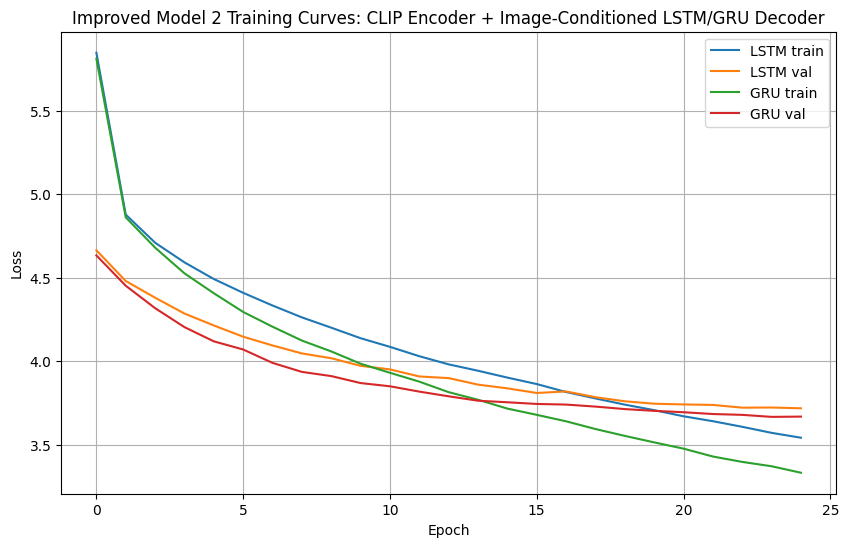

In [ ]:
plt.figure(figsize=(10, 6))
for decoder_type, hist in histories.items():
    plt.plot(hist['train_loss'], label=f'{decoder_type.upper()} train')
    plt.plot(hist['val_loss'], label=f'{decoder_type.upper()} val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Improved Model 2 Training Curves: CLIP Encoder + Image-Conditioned LSTM/GRU Decoder')
plt.legend()
plt.grid(True)
plt.show()

## 17. Caption generation function

The generation is greedy but includes simple restrictions to avoid repeated generic phrases.

In [ ]:
def would_repeat_bigram(tokens, candidate_id):
    if len(tokens) < 2:
        return False
    new_bigram = (tokens[-1], int(candidate_id))
    existing = set((tokens[i], tokens[i+1]) for i in range(len(tokens)-1))
    return new_bigram in existing


@torch.no_grad()
def generate_caption(decoder, image_tensor, max_words=MAX_CAPTION_WORDS, block_repeated_bigrams=True):
    decoder.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)
    image_features = get_image_features(image_tensor)

    tokens = [BOS_IDX]

    for _ in range(max_words):
        input_ids = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)
        logits = decoder(input_ids, image_features)
        next_logits = logits[0, -1, :].clone()

        # Avoid special tokens that should not be generated in the middle.
        next_logits[PAD_IDX] = -1e9
        next_logits[BOS_IDX] = -1e9
        next_logits[UNK_IDX] = -1e9

        if block_repeated_bigrams and len(tokens) >= 2:
            sorted_ids = torch.argsort(next_logits, descending=True)
            next_id = None
            for candidate in sorted_ids[:50]:
                candidate = int(candidate.item())
                if not would_repeat_bigram(tokens, candidate):
                    next_id = candidate
                    break
            if next_id is None:
                next_id = int(sorted_ids[0].item())
        else:
            next_id = int(torch.argmax(next_logits).item())

        if next_id == EOS_IDX:
            break
        tokens.append(next_id)

    return decode_ids(tokens)

## 18. Simple evaluation metrics

These are lightweight BLEU-1 and ROUGE-L implementations, so we do not need extra installations.

In [ ]:
def lcs_length(a, b):
    dp = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            if a[i-1] == b[j-1]:
                dp[i][j] = dp[i-1][j-1] + 1
            else:
                dp[i][j] = max(dp[i-1][j], dp[i][j-1])
    return dp[-1][-1]


def bleu1(reference, prediction):
    ref = tokenize(reference)
    pred = tokenize(prediction)
    if len(pred) == 0:
        return 0.0
    ref_counts = Counter(ref)
    overlap = 0
    for w in pred:
        if ref_counts[w] > 0:
            overlap += 1
            ref_counts[w] -= 1
    precision = overlap / len(pred)
    bp = 1.0 if len(pred) > len(ref) else math.exp(1 - len(ref) / max(len(pred), 1))
    return bp * precision


def rouge_l(reference, prediction):
    ref = tokenize(reference)
    pred = tokenize(prediction)
    if len(ref) == 0 or len(pred) == 0:
        return 0.0
    lcs = lcs_length(ref, pred)
    recall = lcs / len(ref)
    precision = lcs / len(pred)
    if recall + precision == 0:
        return 0.0
    return 2 * recall * precision / (recall + precision)


@torch.no_grad()
def evaluate_generator(decoder, dataset):
    refs, preds = [], []
    for i in range(len(dataset)):
        item = dataset[i]
        pred = generate_caption(decoder, item['image'], max_words=MAX_CAPTION_WORDS)
        ref = item['clean_caption']
        refs.append(ref)
        preds.append(pred)

    return {
        'BLEU-1': float(np.mean([bleu1(r, p) for r, p in zip(refs, preds)])),
        'ROUGE-L': float(np.mean([rouge_l(r, p) for r, p in zip(refs, preds)])),
        'refs': refs,
        'preds': preds,
    }

## 19. CLIP retrieval baseline

Because the dataset is small, generation can collapse into common sentence patterns.

This baseline uses CLIP to retrieve the most visually matching training caption instead of generating from zero.

This is useful for comparison:

```text
image → CLIP image embedding → nearest CLIP text caption
```

In [ ]:
clip_tokenizer = CLIPTokenizer.from_pretrained(CLIP_MODEL_NAME)


@torch.no_grad()
def extract_clip_text_features(clip_model, tokens):
    """
    Safely extract projected CLIP text features.
    This avoids the BaseModelOutputWithPooling issue.
    """
    output = clip_model.get_text_features(**tokens)

    # Normal case: already tensor
    if torch.is_tensor(output):
        return output

    # If output object has text_embeds
    if hasattr(output, "text_embeds"):
        return output.text_embeds

    # Manual fallback: use CLIP text model + text projection
    text_outputs = clip_model.text_model(
        input_ids=tokens["input_ids"],
        attention_mask=tokens["attention_mask"]
    )
    pooled = text_outputs.pooler_output

    if hasattr(clip_model, "text_projection"):
        return clip_model.text_projection(pooled)

    return pooled


@torch.no_grad()
def get_clip_text_features(texts, batch_size=64):
    all_features = []

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        tokens = clip_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=77,
            return_tensors="pt"
        ).to(device)

        feats = extract_clip_text_features(clip_model, tokens)
        feats = feats / feats.norm(dim=-1, keepdim=True).clamp(min=1e-8)

        all_features.append(feats.cpu())

    return torch.cat(all_features, dim=0)


# Use unique training captions as the retrieval bank.
retrieval_captions = sorted(train_df["clean_caption"].dropna().unique().tolist())
print("Retrieval caption bank size:", len(retrieval_captions))

retrieval_text_features = get_clip_text_features(retrieval_captions).to(device)
print("Text feature matrix:", retrieval_text_features.shape)


@torch.no_grad()
def retrieve_caption(image_tensor, top_k=1):
    image_features = get_image_features(image_tensor.unsqueeze(0).to(device))

    # Safety check
    if image_features.shape[-1] != retrieval_text_features.shape[-1]:
        raise ValueError(
            f"Image feature dim {image_features.shape[-1]} does not match "
            f"text feature dim {retrieval_text_features.shape[-1]}. "
            "Use projected CLIP image features and projected CLIP text features."
        )

    sims = image_features @ retrieval_text_features.T
    top = torch.topk(sims.squeeze(0), k=top_k)

    indices = top.indices.cpu().tolist()
    scores = top.values.cpu().tolist()

    return [(retrieval_captions[i], scores[j]) for j, i in enumerate(indices)]


def evaluate_retrieval(dataset):
    refs, preds = [], []

    for i in range(len(dataset)):
        item = dataset[i]
        pred = retrieve_caption(item["image"], top_k=1)[0][0]
        ref = item["clean_caption"]

        refs.append(ref)
        preds.append(pred)

    return {
        "BLEU-1": float(np.mean([bleu1(r, p) for r, p in zip(refs, preds)])),
        "ROUGE-L": float(np.mean([rouge_l(r, p) for r, p in zip(refs, preds)])),
        "refs": refs,
        "preds": preds,
    }

Retrieval caption bank size: 1283
Text feature matrix: torch.Size([1283, 512])


## 20. Evaluate LSTM, GRU, and retrieval baseline

The comparison helps us decide whether generation or retrieval is better for this small dataset.

In [ ]:
results = {}

for decoder_type, decoder in trained_models.items():
    eval_result = evaluate_generator(decoder, test_dataset)
    results[decoder_type.upper()] = {
        'BLEU-1': eval_result['BLEU-1'],
        'ROUGE-L': eval_result['ROUGE-L'],
        'best_val_loss': best_info[decoder_type]['best_val_loss'],
        'best_epoch': best_info[decoder_type]['best_epoch'],
    }

retrieval_result = evaluate_retrieval(test_dataset)
results['CLIP Retrieval'] = {
    'BLEU-1': retrieval_result['BLEU-1'],
    'ROUGE-L': retrieval_result['ROUGE-L'],
    'best_val_loss': None,
    'best_epoch': None,
}

comparison_df = pd.DataFrame(results).T
print(comparison_df)

comparison_path = os.path.join(EXPORT_DIR, 'model2_comparison_results.csv')
comparison_df.to_csv(comparison_path)
print('Saved comparison to:', comparison_path)

                  BLEU-1   ROUGE-L  best_val_loss  best_epoch
LSTM            0.203115  0.220480       3.717790        25.0
GRU             0.194250  0.203196       3.666389        24.0
CLIP Retrieval  0.154753  0.174068            NaN         NaN
Saved comparison to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru_improved/model2_comparison_results.csv


## 21. Show random qualitative samples

Every time you run this cell, it shows **different random test samples**.

This is intentional, so we can inspect different examples without changing the code.

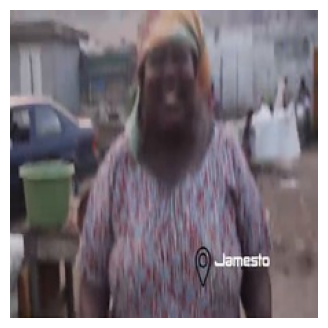

GT       : black woman wears in floral dress in the fish market
LSTM     : a man in a black shirt is talking in front of a car
GRU      : a man is holding a large and showing her house
Retrieval: woman carries a large sack on her head (score=0.307)
Top 3 retrieval options:
  1. woman carries a large sack on her head  | score=0.307
  2. old woman is showing off her roof while wearing a white mask  | score=0.296
  3. woman is walking down the street with her head up  | score=0.296
------------------------------------------------------------------------------------------------------------------------


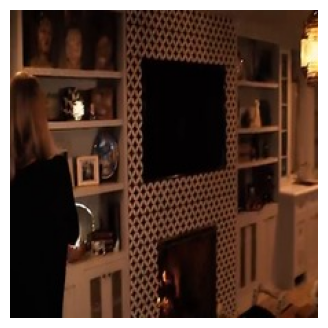

GT       : singer giving a quick interview in her elegant house
LSTM     : a woman is showing her hair in a white
GRU      : a woman is showing her smoothie and drinks it
Retrieval: a blonde woman is showing her inside house (score=0.313)
Top 3 retrieval options:
  1. a blonde woman is showing her inside house  | score=0.313
  2. the woman in a black coat opens the door to her room and goes inside  | score=0.301
  3. a woman showing the inside of a hotel room  | score=0.300
------------------------------------------------------------------------------------------------------------------------


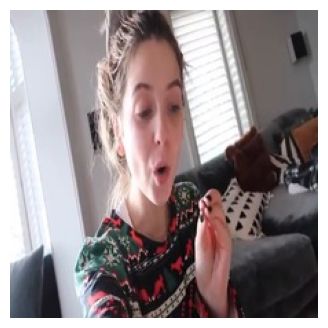

GT       : a girl in a christmas sweater looks to be in a positive mood
LSTM     : a woman in a black top is talking in front of a car
GRU      : a woman in a black top is talking to the camera while talking in the
Retrieval: young mother making vlog while her child is sleeping (score=0.301)
Top 3 retrieval options:
  1. young mother making vlog while her child is sleeping  | score=0.301
  2. vlogger shows the shoes on the floor then picks some up  | score=0.295
  3. woman with floral top eats her food  | score=0.294
------------------------------------------------------------------------------------------------------------------------


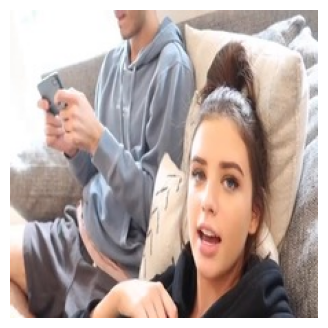

GT       : a girl in black hoodie is talking in front of the camera while talking to the boy next to her
LSTM     : a woman in a black top is talking to her camera
GRU      : a woman in a black top is talking to the camera while talking in the
Retrieval: girl sits next to her mom on their couch (score=0.311)
Top 3 retrieval options:
  1. girl sits next to her mom on their couch  | score=0.311
  2. girl in pig tails sits on the couch next to her mom  | score=0.306
  3. a young woman preparing to go somewhere physically pulls her sister into the video  | score=0.305
------------------------------------------------------------------------------------------------------------------------


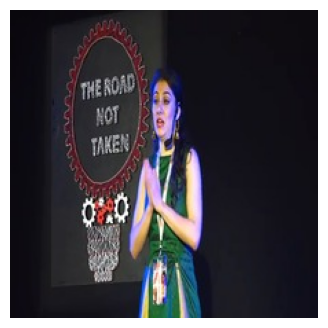

GT       : woman gives a tedtalk under blue light
LSTM     : a woman in a black top is talking to a camera in front of a
GRU      : a woman is showing her smoothie and a white mask
Retrieval: a young theatre actress playing the snow queen talks about the amazing feedback she got from her i
hate my body video (score=0.300)
Top 3 retrieval options:
  1. a young theatre actress playing the snow queen talks about the amazing feedback she got from her i hate my body video  | score=0.300
  2. woman monologues to camera wearing a mic on her lapel  | score=0.297
  3. woman monologues while driving a car  | score=0.287
------------------------------------------------------------------------------------------------------------------------


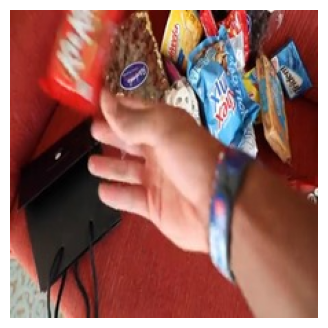

GT       : a man walks through a hotel to his room and looks through some snacks
LSTM     : a woman is showing her hair in a car
GRU      : a woman is showing her smoothie and drinks it
Retrieval: vlogger flips through the different stickers of a pack (score=0.345)
Top 3 retrieval options:
  1. vlogger flips through the different stickers of a pack  | score=0.345
  2. a woman is reviewing the various snacks she has by her hotel bed  | score=0.311
  3. woman takes the food out of a bag and puts it away  | score=0.303
------------------------------------------------------------------------------------------------------------------------


In [ ]:
NUM_RANDOM_SAMPLES = 6
sample_count = min(NUM_RANDOM_SAMPLES, len(test_dataset))

# SystemRandom does not use the fixed training seed, so samples change every run.
sample_indices = random.SystemRandom().sample(range(len(test_dataset)), sample_count)

for idx in sample_indices:
    item = test_dataset[idx]
    image_pil = Image.open(item['image_path']).convert('RGB')

    lstm_pred = generate_caption(trained_models['lstm'], item['image'], max_words=MAX_CAPTION_WORDS)
    gru_pred = generate_caption(trained_models['gru'], item['image'], max_words=MAX_CAPTION_WORDS)
    retrieval_top3 = retrieve_caption(item['image'], top_k=3)

    plt.figure(figsize=(5, 4))
    plt.imshow(image_pil)
    plt.axis('off')
    plt.show()

    print('GT       :', textwrap.fill(item['clean_caption'], width=100))
    print('LSTM     :', textwrap.fill(lstm_pred, width=100))
    print('GRU      :', textwrap.fill(gru_pred, width=100))
    print('Retrieval:', textwrap.fill(retrieval_top3[0][0], width=100), f'(score={retrieval_top3[0][1]:.3f})')
    print('Top 3 retrieval options:')
    for rank, (cap, score) in enumerate(retrieval_top3, start=1):
        print(f'  {rank}. {cap}  | score={score:.3f}')
    print('-' * 120)

## 22. Save metadata

This saves the vocabulary, configuration, and comparison results for later use.

In [ ]:
metadata = {
    'project_root': PROJECT_ROOT,
    'pairs_path': PAIRS_PATH,
    'clip_model_name': CLIP_MODEL_NAME,
    'max_caption_words': MAX_CAPTION_WORDS,
    'min_word_freq': MIN_WORD_FREQ,
    'max_vocab_size': MAX_VOCAB_SIZE,
    'vocab_size': VOCAB_SIZE,
    'best_info': best_info,
    'results': results,
    'note': 'CLIP is frozen. LSTM/GRU decoders are trained. Retrieval baseline added for small data comparison.'
}

metadata_path = os.path.join(EXPORT_DIR, 'model2_metadata.json')
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)

vocab_path = os.path.join(EXPORT_DIR, 'vocab.json')
with open(vocab_path, 'w', encoding='utf-8') as f:
    json.dump({'itos': itos, 'stoi': stoi}, f, indent=2)

print('Saved metadata:', metadata_path)
print('Saved vocab:', vocab_path)

Saved metadata: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru_improved/model2_metadata.json
Saved vocab: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru_improved/vocab.json


## 23. Result notes template

After running the notebook, fill this section using your actual outputs.

Suggested conclusion structure:

```text
The first CLIP + LSTM/GRU generation attempt showed language-prior collapse, where the decoder generated repeated generic sentences such as "a woman is..." or "a man is...". This happened because the dataset is small and many query targets are not clean image captions.

To improve this, the decoder was modified so that the CLIP image feature is concatenated with the word embedding at every decoding step. This keeps the image signal available throughout generation. We also added a CLIP retrieval baseline, which retrieves the most visually related caption from the training caption bank.

The LSTM, GRU, and retrieval results were compared using validation loss, BLEU-1, ROUGE-L, and qualitative examples. If retrieval performs better, this suggests that for a small dataset, retrieving a visually similar query can be more reliable than generating a sentence from scratch.
```